In [11]:
!pip install -q astroquery gala galstreams
!pip install numpy==2.2.6

from __future__ import annotations
import time, threading

from pathlib import Path
from dataclasses import dataclass
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks, peak_widths

import astropy.units as u
from astropy.coordinates import SkyCoord
from gala.coordinates import GD1Koposov10
from astroquery.gaia import Gaia
import galstreams


In [12]:
STREAMS_DATA_DIR = Path.cwd() / "streams_data_cache"
STREAMS_DATA_DIR.mkdir(parents=True, exist_ok=True)

CACHED_STREAMS_FILE = STREAMS_DATA_DIR / "Streams.pkl"

path= '/content/drive/MyDrive/Streams.csv'

if CACHED_STREAMS_FILE.exists():
    print(f"Loading df1 from cache: {CACHED_STREAMS_FILE}")
    df1 = pd.read_pickle(CACHED_STREAMS_FILE)

else:
    print(f"Cache not found. Mounting Google Drive and loading from {path}")
    from google.colab import drive
    drive.mount('/content/drive')

    df1 = pd.read_csv(path, engine='python', on_bad_lines='skip')

    # Save the DataFrame to cache as a pickle file
    print(f"Saving df1 to cache: {CACHED_STREAMS_FILE}")
    df1.to_pickle(CACHED_STREAMS_FILE)

display(df1.head())

Loading df1 from cache: /content/streams_data_cache/Streams.pkl


,ra,dec,parallax,pmra,pmdec,g,bp_rp,stream
0,0.131771,8.022269,-0.523,-0.338,1.390,19.35,0.74,1
1,0.328548,7.886247,0.045,-0.683,1.425,19.48,0.59,1
2,0.714213,7.207192,0.090,-0.553,1.405,15.83,1.04,1
3,0.714858,7.301568,-0.001,-0.439,1.322,18.75,0.83,1
4,0.992495,6.646490,-0.413,-0.760,1.801,19.04,0.68,1


In [13]:
STREAM_IDS = {
    15: "Indus-S19",
    20: "C-12-I24",
    41: "Ylgr-I21",
    48: "Orphan-K23",
    69: "NGC6397-I21",
    86: "Jhelum-a-B19",
}

mw_streams = galstreams.MWStreams()

dfs_by_name = {}
for sid, name in STREAM_IDS.items():
    stars = df1.loc[df1["stream"] == sid].copy()
    if stars.empty:
        print(f"{name} (id {sid}): no stars in df1, skipping")
        continue

    frame = mw_streams[name].stream_frame
    c = SkyCoord(ra=stars["ra"].to_numpy() * u.deg,
                 dec=stars["dec"].to_numpy() * u.deg, frame="icrs")
    sc = c.transform_to(frame)

    # wrap phi1 to (-180, 180] so it is continuous across 0
    stars["phi1"] = sc.phi1.wrap_at(180 * u.deg).degree
    stars["phi2"] = sc.phi2.degree

    dfs_by_name[name] = stars
    print(f"{name}: {len(stars)} stars, phi1 in [{stars.phi1.min():.1f}, {stars.phi1.max():.1f}]")

Initializing galstreams library from master_log... 
Indus-S19: 1021 stars, phi1 in [-13.0, 77.0]
C-12-I24: 929 stars, phi1 in [-14.1, 13.8]
Ylgr-I21: 919 stars, phi1 in [-23.6, 25.1]
Orphan-K23: 867 stars, phi1 in [-67.6, 130.3]
NGC6397-I21: 1207 stars, phi1 in [-6.7, 25.7]
Jhelum-a-B19: 986 stars, phi1 in [-71.5, 25.8]


In [14]:
# -----------------------------------------------------------------------
# Stream fit
# -----------------------------------------------------------------------
def _gauss_c(x, amp, mu, sigma, c=0.0):
    """Gaussian + constant background."""
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + c


def fit_stream_track(
    df: pd.DataFrame,
    bin_width: float = 1.0,
    poly_order: int = 2,
    min_points_per_bin: int = 5,
    n_iter: int = 4,
    clip: float = 3.0,
) -> dict:
    """
    Iteratively fit a polynomial track phi2(phi1) to binned medians, clipping
    off-track contaminants each pass, then MEASURE the stream width from the
    residuals of the surviving stars.
    """
    phi1 = df["phi1"].values
    phi2 = df["phi2"].values
    sel = np.ones(len(df), dtype=bool)

    for _ in range(n_iter):
        edges = np.arange(phi1[sel].min(), phi1[sel].max() + bin_width, bin_width)
        centres, phi2_med = [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            m = sel & (phi1 >= lo) & (phi1 < hi)
            if m.sum() > min_points_per_bin:
                centres.append(0.5 * (lo + hi))
                phi2_med.append(np.median(phi2[m]))
        centres, phi2_med = np.array(centres), np.array(phi2_med)
        if len(centres) <= poly_order:
            raise ValueError(
                f"Only {len(centres)} usable bins for a poly_order={poly_order} fit; "
                "increase bin_width or lower min_points_per_bin / poly_order."
            )

        coef = np.polyfit(centres, phi2_med, poly_order)
        poly = np.poly1d(coef)

        resid_all = phi2 - poly(phi1)
        med = np.median(resid_all[sel])
        sig_mad = 1.4826 * np.median(np.abs(resid_all[sel] - med))
        sig_mad = max(sig_mad, 1e-3)
        sel = np.abs(resid_all - med) < clip * sig_mad

    residuals = phi2 - poly(phi1)

    # Gaussian + const fit to the residual histogram
    rng = 5 * sig_mad
    hist, edges_h = np.histogram(residuals, bins=50, range=(-rng, rng), density=True)
    centers_h = 0.5 * (edges_h[:-1] + edges_h[1:])
    try:
        p0 = [hist.max(), 0.0, sig_mad, hist.min()]
        popt, _ = curve_fit(
            _gauss_c, centers_h, hist, p0=p0,
            bounds=([0, -rng, 0.01, 0], [np.inf, rng, 3 * rng, np.inf]),
        )
        sigma_fit, mu_fit = abs(popt[2]), popt[1]
    except RuntimeError:
        popt, sigma_fit, mu_fit = None, sig_mad, med   # fall back to robust MAD estimate

    return {
        "poly": poly,
        "poly_coef": coef,
        "residuals": residuals,
        "popt": popt,
        "centres": centres,
        "phi2_med": phi2_med,
        "residual_sigma": sigma_fit,
        "residual_mu": mu_fit,
        "sigma_mad": sig_mad,
        "suggested_width_2sigma": 2 * sigma_fit,
        "suggested_width_3sigma": 3 * sigma_fit,
    }


def select_by_track_width(df: pd.DataFrame, poly: np.poly1d, width: float,
                          return_all: bool = False) -> pd.DataFrame:
    """Keep stars within +/- width of the track (pass return_all=True to skip the cut)."""
    if return_all:
        return df.copy()
    mask = np.abs(df["phi2"] - poly(df["phi1"])) < width
    return df[mask].copy()


# -----------------------------------------------------------------------
# Underdensities
# -----------------------------------------------------------------------
def _phi1_bounds(phi, exclude_first_pct, exclude_last_pct):
    """Same convention as the GD-1 pipeline: trim a % of the phi1 extent at each end."""
    lo_, hi_ = phi.min(), phi.max()
    ext = hi_ - lo_
    return lo_ + ext * exclude_first_pct / 100.0, hi_ - ext * exclude_last_pct / 100.0


def find_underdensities(
    stream_df,
    bin_width=0.5,
    smoothing_sigmas=(1.0, 2.0, 3.0),   # in bins
    baseline_poly_order=3,
    min_significance=2.0,
    n_clip_iter=6,
    merge_tol=1.0,                      # minimum centre separation between kept gaps
    exclude_first_pct=5.0,
    exclude_last_pct=5.0,
    min_base_counts=0.0,                # 0 = empty / zero-baseline bins are valid gap candidates
    return_diagnostics=False,
) -> pd.DataFrame:

    phi = stream_df["phi1"].values
    edges = np.arange(phi.min(), phi.max() + bin_width, bin_width)
    counts, edges = np.histogram(phi, bins=edges)
    centers = 0.5 * (edges[:-1] + edges[1:])

    lo, hi = _phi1_bounds(phi, exclude_first_pct, exclude_last_pct)
    use = (centers >= lo) & (centers <= hi)

    # robust baseline via iterative sigma clipping, fitted on `use` bins only
    keep = use.copy()
    for _ in range(n_clip_iter):
        if keep.sum() <= baseline_poly_order + 1:
            break
        coef = np.polyfit(centers[keep], counts[keep], baseline_poly_order)
        base = np.clip(np.polyval(coef, centers), 1e-3, None)
        keep = (np.abs(counts - base) < 2.5 * np.sqrt(base)) & use

    use = use & (base >= min_base_counts)

    rows, diag = [], {}
    for s in smoothing_sigmas:
        smooth = gaussian_filter1d(counts.astype(float), s, mode="nearest")
        residual = smooth - base
        noise = np.sqrt(base / (2 * np.sqrt(np.pi) * s))
        signif = -residual / noise              # negative = overdensity
        signif[~use] = 0.0

        # Peak finding / widths on the underdensity side only. Without the clip,
        # huge overdensities (-300 sigma) make peak_widths span the whole stream.
        sig_pos = np.clip(signif, 0.0, None)
        padded = np.r_[0.0, sig_pos, 0.0]
        idx, _ = find_peaks(padded, height=min_significance, prominence=1.0)
        idx = idx - 1
        if len(idx):
            widths = peak_widths(padded, idx + 1, rel_height=0.5)[0]
            for i, w in zip(idx, widths):
                half = 0.5 * w * bin_width
                rows.append(dict(
                    phi1_center=centers[i],
                    depth_frac=residual[i] / base[i],
                    width=w * bin_width,
                    phi1_start=max(centers[i] - half, lo),
                    phi1_end=min(centers[i] + half, hi),
                    significance_sigma=signif[i],
                    smoothing_sigma=s,
                ))
        diag[s] = dict(smooth=smooth, signif=signif)

    cols = ["phi1_center", "depth_frac", "width", "phi1_start", "phi1_end",
            "significance_sigma", "smoothing_sigma"]
    if not rows:
        gaps = pd.DataFrame(columns=cols)
    else:
        # Most significant first; keep a candidate only if it overlaps nothing already kept.
        cand = pd.DataFrame(rows).sort_values("significance_sigma", ascending=False)
        kept = []
        for _, r in cand.iterrows():
            clash = any(
                (r.phi1_start < k.phi1_end and r.phi1_end > k.phi1_start)
                or abs(r.phi1_center - k.phi1_center) <= merge_tol
                for k in kept
            )
            if not clash:
                kept.append(r)
        gaps = pd.DataFrame(kept).sort_values("phi1_center").reset_index(drop=True)

    if return_diagnostics:
        return gaps, dict(centers=centers, counts=counts, base=base,
                          per_scale=diag, use=use,
                          min_significance=min_significance, window=(lo, hi))
    return gaps


# printing one line per entry, to avoid wrapping
def print_table(df, cols=None, ndigits=2):
    if cols is not None:
        df = df[cols]
    print(df.to_string(index=False,
                       float_format=lambda x: f"{x:.{ndigits}f}"))


GAP_COLS = ["stream", "phi1_center", "phi1_start", "phi1_end", "width",
            "depth_frac", "significance_sigma", "smoothing_sigma"]
SUMMARY_COLS = ["stream", "n_input", "n_on_track", "track_width_deg",
                "residual_sigma", "n_underdensities"]

# -----------------------------------------------------------------------
# Registry / loading
# -----------------------------------------------------------------------
STREAM_IDS = {
    15: "Indus-S19",
    20: "C-12-I24",
    41: "Ylgr-I21",
    48: "Orphan-K23",
    69: "NGC6397-I21",
    86: "Jhelum-a-B19",
}

PHI1_CUTS = {
    "NGC6397-I21": (-2.0, None),     # reject phi1 < -2
}

PHI2_CUTS = {
    "Jhelum-a-B19": (-10.0, None),   # reject phi2 < -10
    "Ylgr-I21": (-5.0, None),        # reject phi2 < -5
}

def load_stream_data(stream_name: str) -> pd.DataFrame:
    if stream_name not in dfs_by_name:
        raise KeyError(f"{stream_name} not found in dfs_by_name.")

    df = dfs_by_name[stream_name].dropna(subset=["phi1", "phi2"])

    lo, hi = PHI1_CUTS.get(stream_name, (None, None))
    if lo is not None:
        df = df[df["phi1"] >= lo]
    if hi is not None:
        df = df[df["phi1"] <= hi]

    lo, hi = PHI2_CUTS.get(stream_name, (None, None))
    if lo is not None:
        df = df[df["phi2"] >= lo]
    if hi is not None:
        df = df[df["phi2"] <= hi]

    return df.reset_index(drop=True)


# -----------------------------------------------------------------------
# Per-stream processing
# -----------------------------------------------------------------------
def process_stream(
    stream_name: str,
    df: pd.DataFrame,
    width_sigma: float = 2.0,
    make_plots: bool = True,
    **gap_kwargs,
) -> dict:
    track_fit = fit_stream_track(df, poly_order=3)
    width = width_sigma * track_fit["residual_sigma"]
    on_track = select_by_track_width(df, track_fit["poly"], width)

    underdensities, gap_diag = find_underdensities(
        on_track, return_diagnostics=True, **gap_kwargs
    )
    underdensities["stream"] = stream_name

    if make_plots:
        _plot_stream_diagnostics(stream_name, df, on_track, track_fit, width,
                                 underdensities, gap_diag)
    return {
        "stream": stream_name,
        "n_input": len(df),
        "n_on_track": len(on_track),
        "track_width_deg": width,
        "residual_sigma": track_fit["residual_sigma"],
        "n_underdensities": len(underdensities),
        "underdensities": underdensities,
    }


def _plot_stream_diagnostics(stream_name, full_df, on_track, track_fit, width,
                             underdensities, gap_diag):
    xfit = np.linspace(full_df["phi1"].min(), full_df["phi1"].max(), 300)
    yfit = track_fit["poly"](xfit)
    c = gap_diag["centers"]
    lo, hi = gap_diag["window"]

    fig, (ax1, ax2, ax3) = plt.subplots(
        3, 1, figsize=(12, 10), sharex=True,
        gridspec_kw=dict(height_ratios=[1.3, 1, 1]),
    )

    # (1) spatial selection + track
    ax1.scatter(full_df["phi1"], full_df["phi2"], s=1, alpha=0.3, color="gray", label="All candidates")
    ax1.scatter(on_track["phi1"], on_track["phi2"], s=2, color="C0", label="On-track")
    ax1.plot(xfit, yfit, "r-", lw=2, label="Track fit")
    ax1.fill_between(xfit, yfit - width, yfit + width, color="r", alpha=0.1)
    ax1.set_ylabel(r"$\phi_2$ [deg]")
    ax1.set_title(f"{stream_name}: track fit and underdensities")
    ax1.legend(loc="upper right", fontsize=8)

    # (2) density profile
    ax2.step(c, gap_diag["counts"], where="mid", color="gray", label="Counts")
    for s, d in gap_diag["per_scale"].items():
        ax2.plot(c, d["smooth"], lw=1, label=f"Smoothed (σ={s:g} bins)")
    ax2.plot(c, gap_diag["base"], "k--", label="Baseline")
    ax2.set_ylabel("Counts / bin")
    ax2.legend(loc="upper right", fontsize=8)

    # (3) signed significance: gaps are dips below zero (inverted from the detection statistic)
    for s, d in gap_diag["per_scale"].items():
        ax3.plot(c, -d["signif"], lw=1, label=f"σ={s:g} bins")
    ax3.axhline(-gap_diag["min_significance"], color="k", ls=":", lw=1,
                label=f"-{gap_diag['min_significance']:g}σ threshold")
    ax3.axhline(0, color="k", lw=0.5)
    depth = max((d["signif"].max() for d in gap_diag["per_scale"].values()), default=0)
    ax3.set_ylim(-max(depth * 1.3, gap_diag["min_significance"] + 7), 5)
    ax3.set_ylabel(r"(smoothed − baseline) / noise [$\sigma$]")
    ax3.set_xlabel(r"$\phi_1$ [deg]")
    ax3.legend(loc="upper right", fontsize=8)

    # analysis window
    for a in (ax2, ax3):
        a.axvline(lo, color="k", lw=0.5, ls="--")
        a.axvline(hi, color="k", lw=0.5, ls="--")

    # shade every detected gap
    for _, g in underdensities.iterrows():
        for a in (ax2, ax3):
            a.axvspan(g["phi1_start"], g["phi1_end"], color="tab:red", alpha=0.2)
        ax3.annotate(f"{g['significance_sigma']:.1f}σ",
                     (g["phi1_center"], -g["significance_sigma"]),
                     textcoords="offset points", xytext=(0, -12),
                     ha="center", fontsize=8, color="red")

    fig.tight_layout()
    fig.savefig(f"diagnostics_{stream_name.replace(' ', '_')}.png", dpi=150)
    plt.show()
    plt.close(fig)

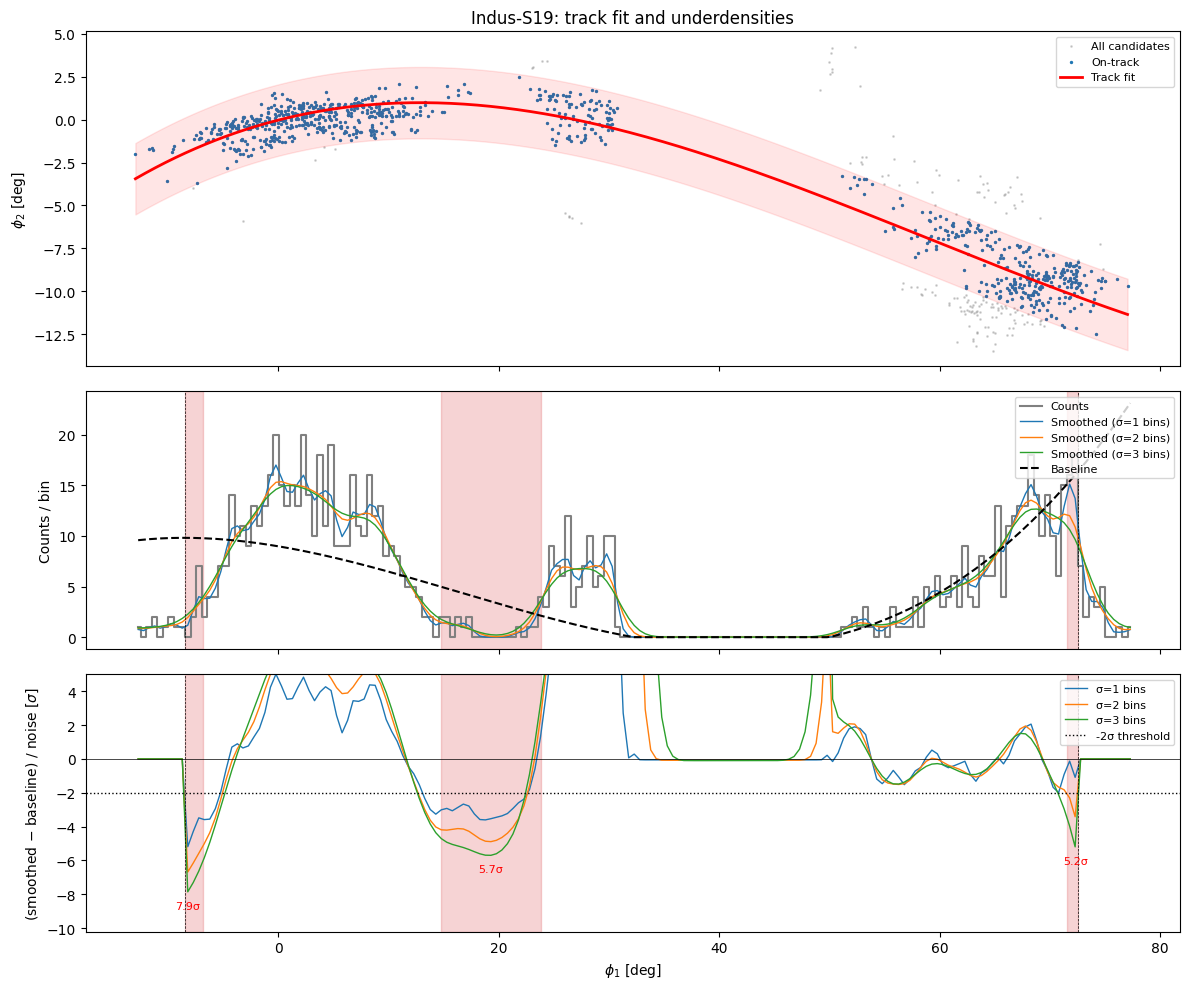

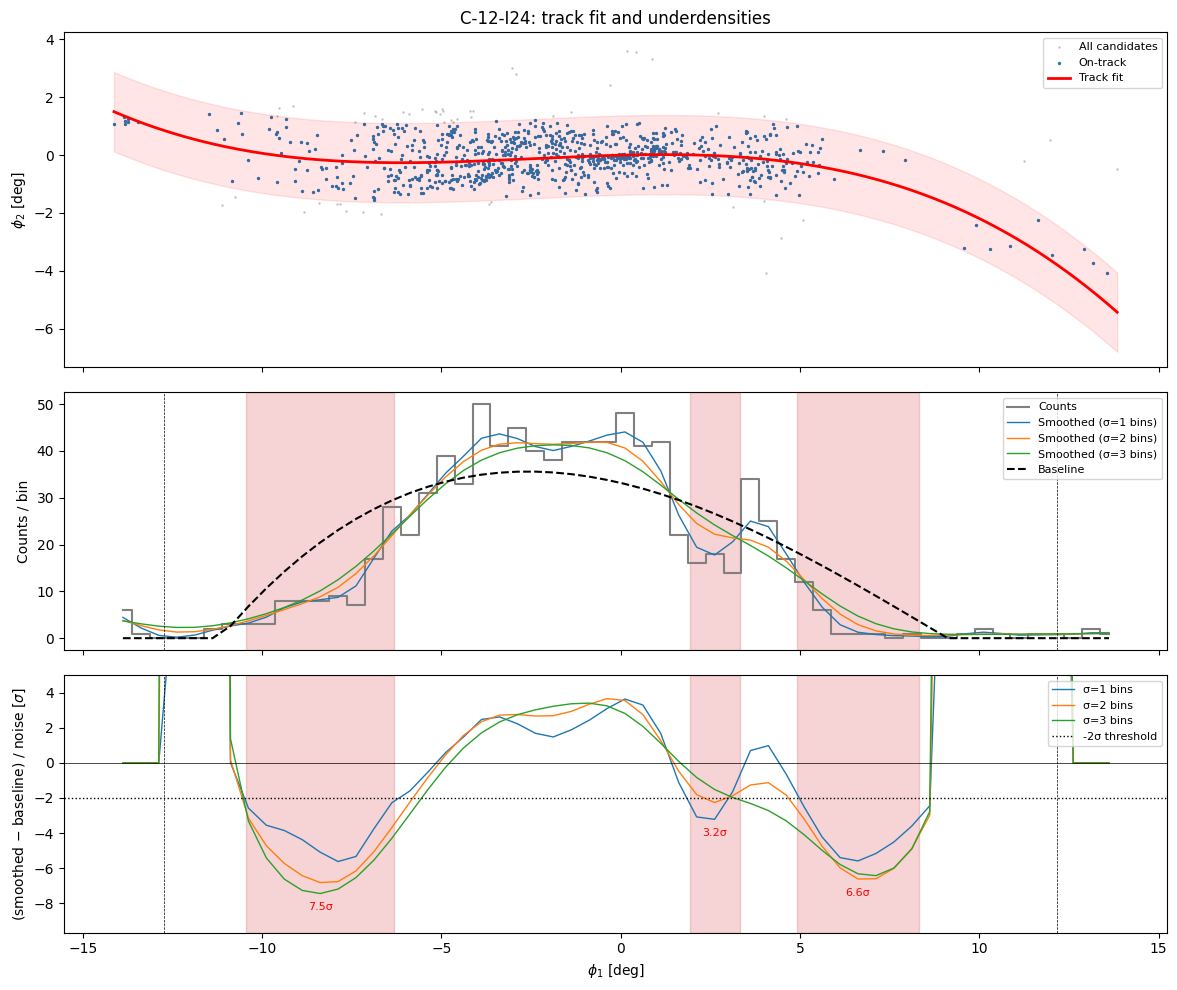

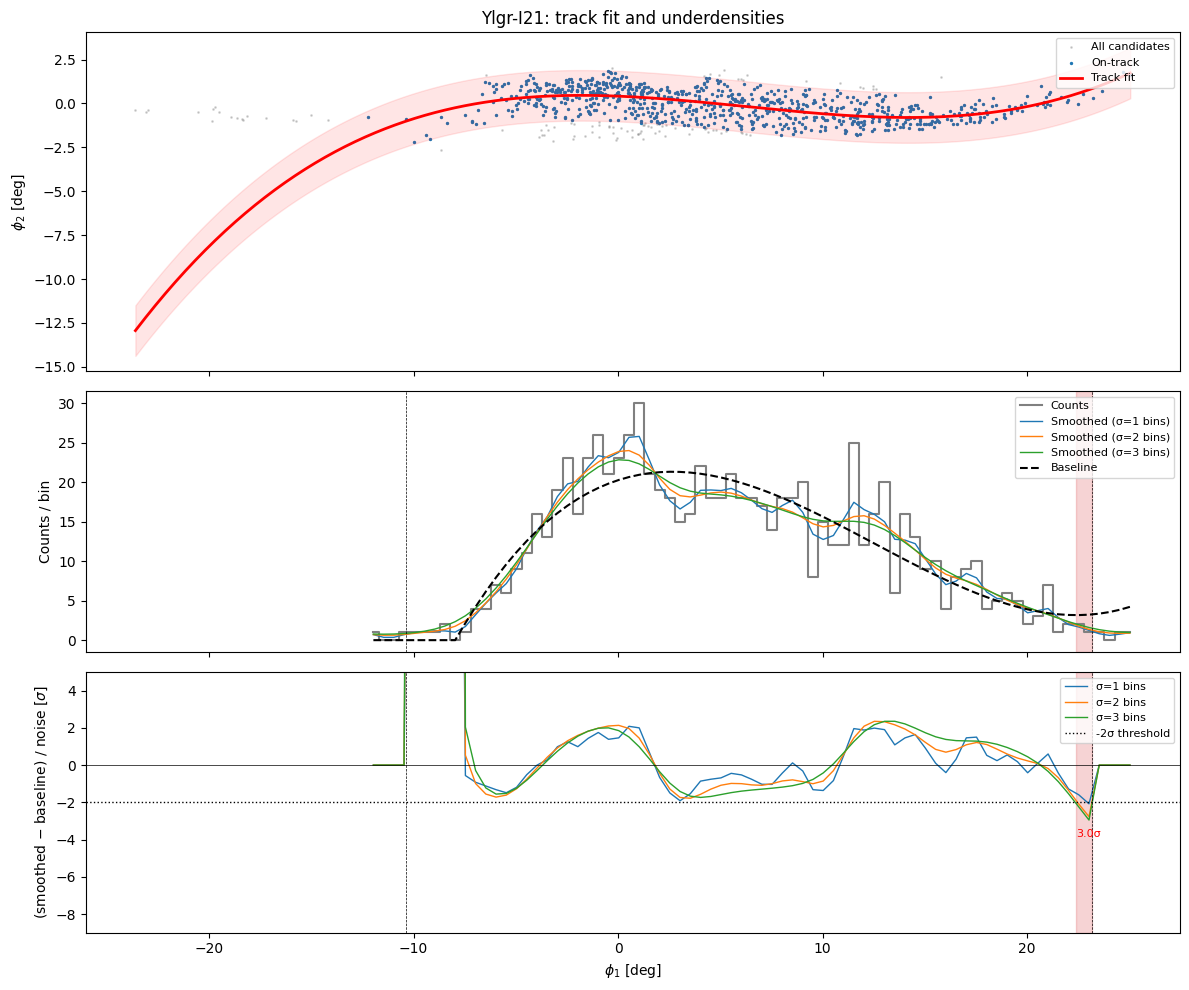

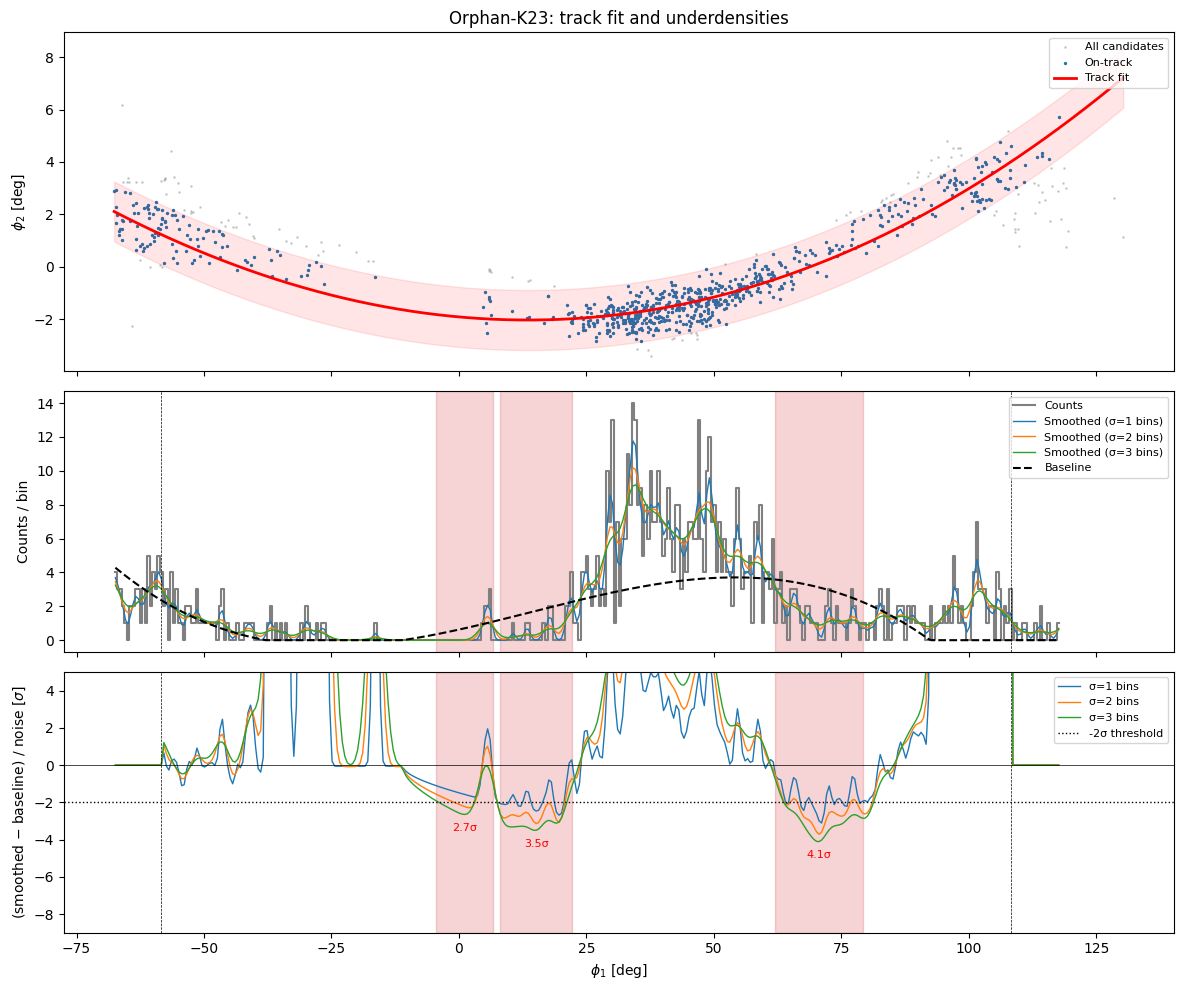

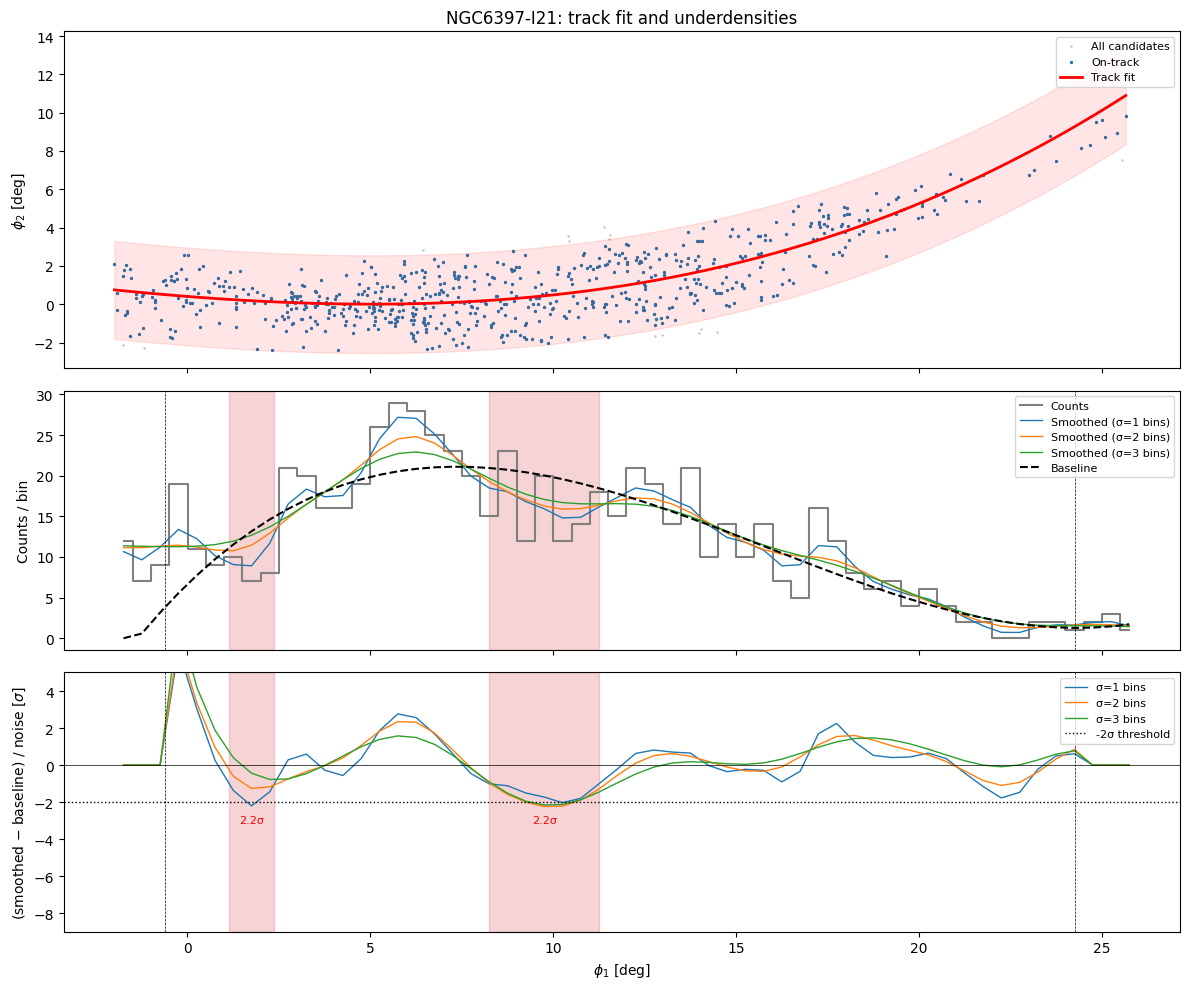

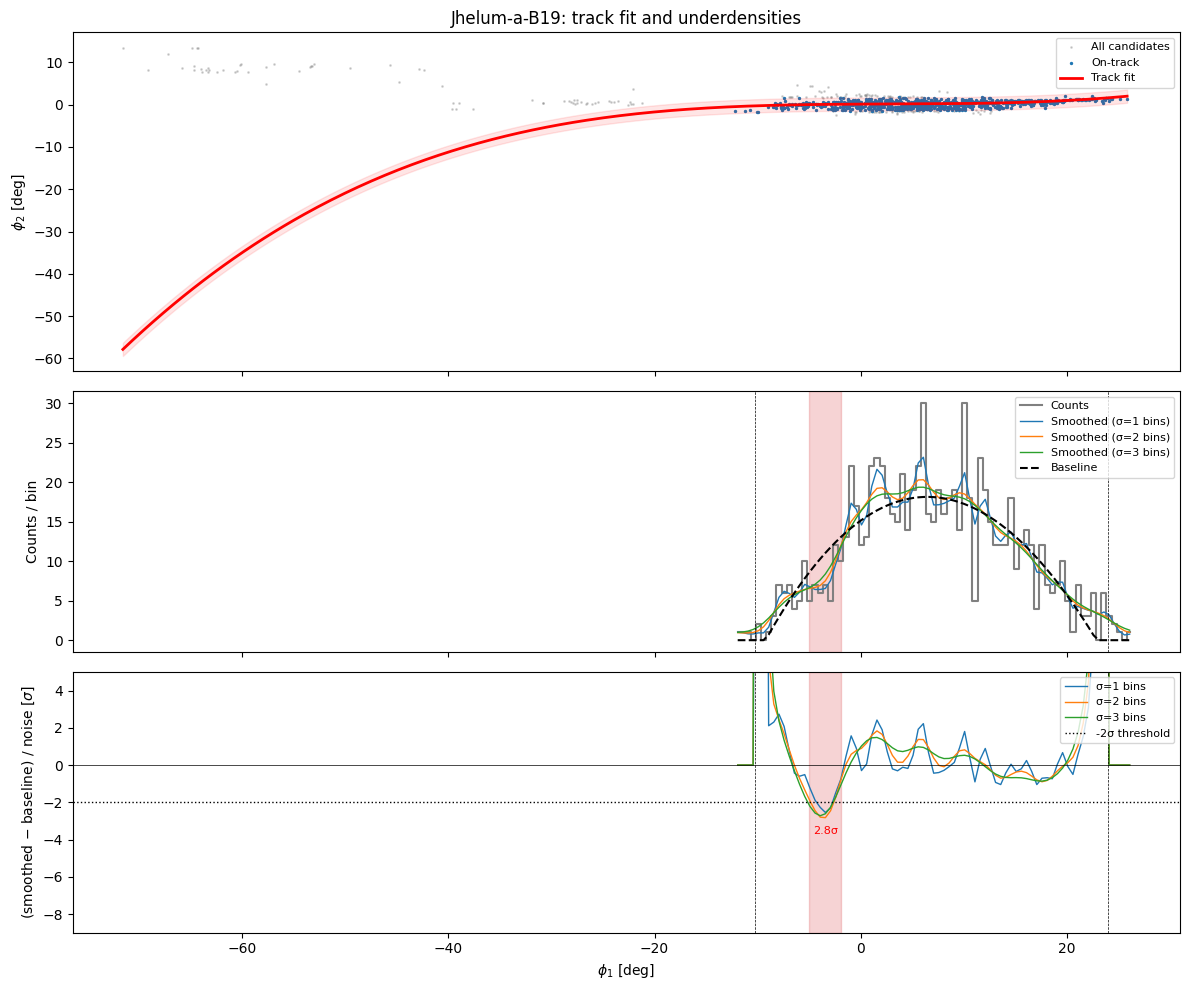

Per-stream summary:
      stream  n_input  n_on_track  track_width_deg  residual_sigma  n_underdensities
   Indus-S19     1021         869             2.08            1.04                 3
    C-12-I24      929         876             1.37            0.69                 3
    Ylgr-I21      919         822             1.44            0.72                 1
  Orphan-K23      867         744             1.14            0.57                 3
 NGC6397-I21      691         677             2.55            1.28                 2
Jhelum-a-B19      986         811             1.56            0.78                 1

All detected gaps:
      stream  phi1_center  phi1_start  phi1_end  width  depth_frac  significance_sigma  smoothing_sigma
   Indus-S19        -8.22       -8.47     -6.85   2.74       -0.77                7.86             3.00
   Indus-S19        19.28       14.76     23.79   9.02       -0.93                5.70             3.00
   Indus-S19        72.28       71.54     72.53   1.4

In [15]:
def run_all_streams(width_sigma: float = 3.0, make_plots: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    summaries = []
    all_gaps = []

    for stream_id, stream_name in STREAM_IDS.items():
        print(f"Processing {stream_name}...")
        try:
            df = load_stream_data(stream_name)
            result = process_stream(stream_name, df, width_sigma=width_sigma, make_plots=make_plots)

            summaries.append({
                "stream": result["stream"],
                "n_input": result["n_input"],
                "n_on_track": result["n_on_track"],
                "track_width_deg": result["track_width_deg"],
                "n_underdensities": result["n_underdensities"],
            })
            all_gaps.append(result["underdensities"])
        except Exception as e:
            print(f"  skipped: {type(e).__name__}: {e}")
            continue

    summary_df = pd.DataFrame(summaries)
    all_gaps_df = pd.concat(all_gaps, ignore_index=True) if all_gaps else pd.DataFrame()

    return summary_df, all_gaps_df

def main():
    results = [process_stream(name, load_stream_data(name)) for name in dfs_by_name]
    summary = pd.DataFrame([{k: v for k, v in r.items() if k != "underdensities"} for r in results])
    all_gaps = pd.concat([r["underdensities"] for r in results], ignore_index=True)
    print("Per-stream summary:")
    print_table(summary, SUMMARY_COLS)
    print("\nAll detected gaps:")
    print_table(all_gaps, GAP_COLS)

main()